Saving Screenshot 2026-03-11 224825.png to Screenshot 2026-03-11 224825.png
Image Shape: (482, 500, 3)
K = 2 | WCSS = 6644.08 | Silhouette = 0.7702 | Calinski-Harabasz = 474665.53
K = 3 | WCSS = 3871.14 | Silhouette = 0.7780 | Calinski-Harabasz = 493650.36
K = 4 | WCSS = 1985.87 | Silhouette = 0.6805 | Calinski-Harabasz = 717789.47
K = 5 | WCSS = 1615.41 | Silhouette = 0.6673 | Calinski-Harabasz = 675617.71
K = 6 | WCSS = 1337.23 | Silhouette = 0.6494 | Calinski-Harabasz = 662948.31
K = 7 | WCSS = 1087.63 | Silhouette = 0.6952 | Calinski-Harabasz = 688457.65
K = 8 | WCSS = 870.65 | Silhouette = 0.6975 | Calinski-Harabasz = 745743.27
K = 9 | WCSS = 650.73 | Silhouette = 0.7197 | Calinski-Harabasz = 883248.09
K = 10 | WCSS = 524.10 | Silhouette = 0.7176 | Calinski-Harabasz = 981257.80


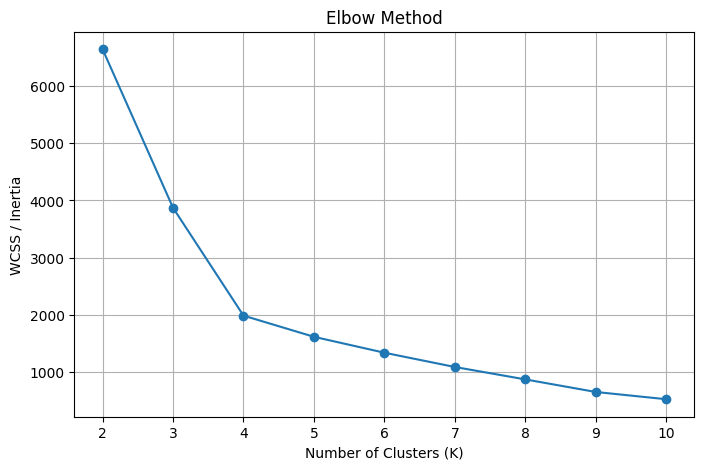

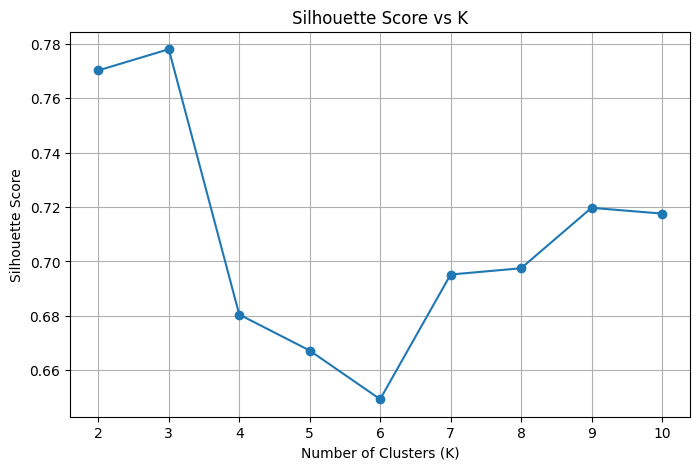

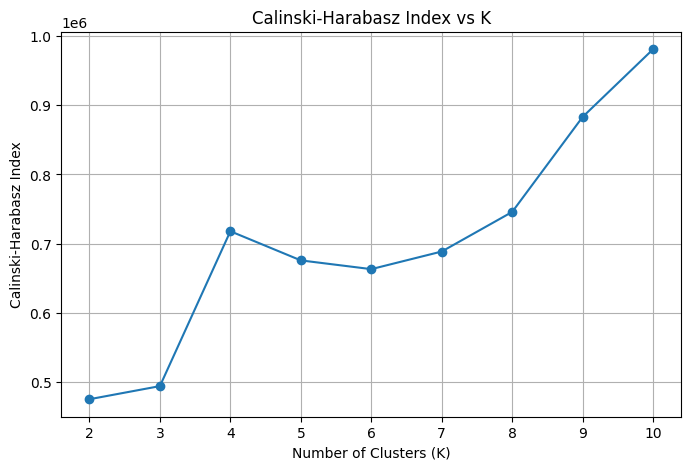


Optimal K = 10


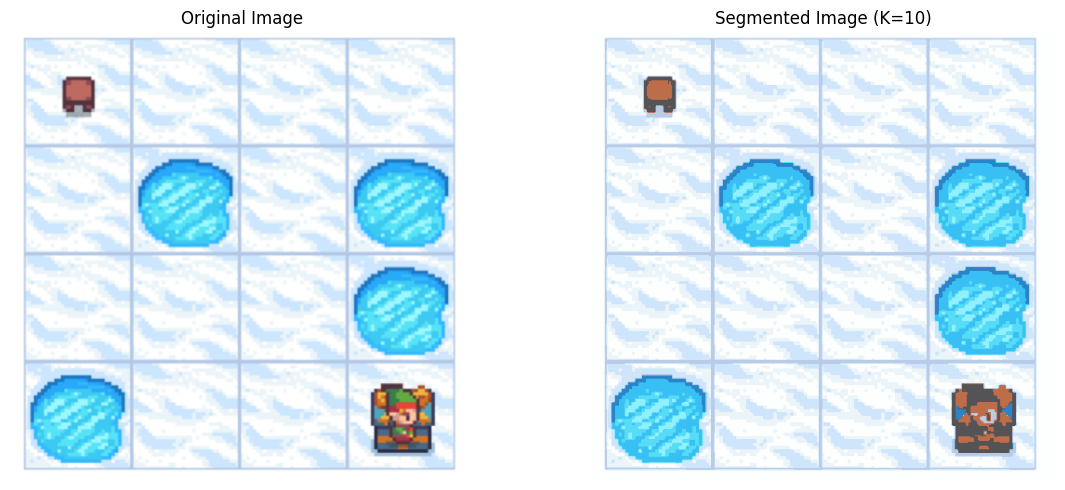

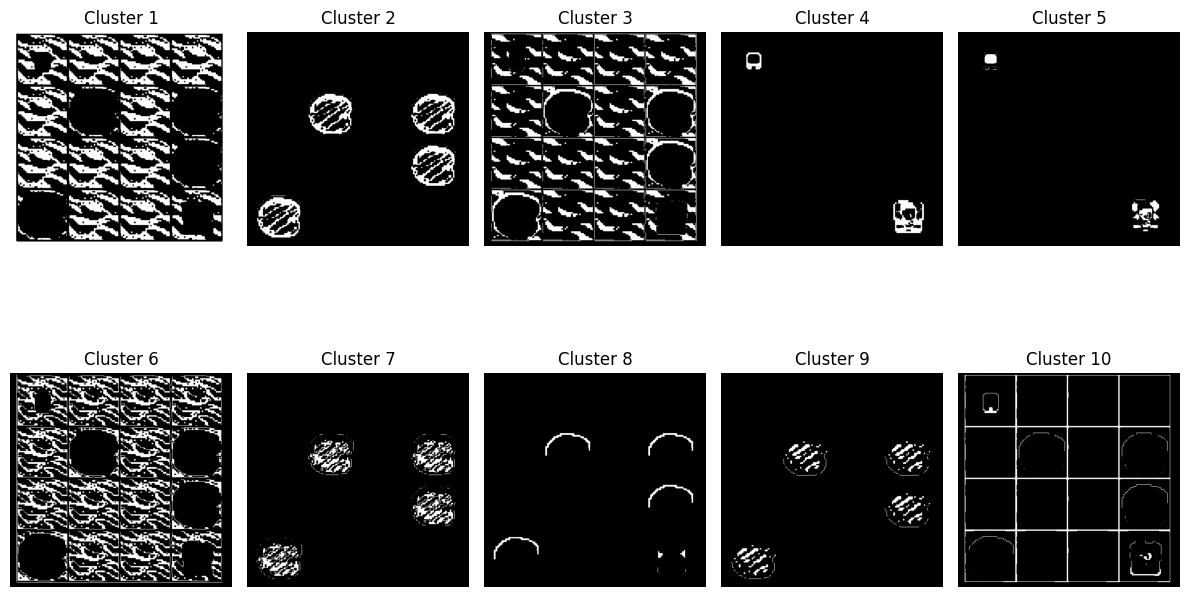

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = Image.open(image_path).convert("RGB")

max_size = 500

if max(image.size) > max_size:
    image.thumbnail((max_size, max_size))

image_array = np.array(image)

print("Image Shape:", image_array.shape)

pixels = image_array.reshape(-1, 3)
pixels_normalized = pixels / 255.0

k_values = range(2, 11)

inertias = []
silhouette_scores = []
calinski_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(pixels_normalized)

    inertias.append(kmeans.inertia_)

    sample_size = min(10000, len(pixels_normalized))

    silhouette = silhouette_score(
        pixels_normalized,
        labels,
        sample_size=sample_size,
        random_state=42
    )

    silhouette_scores.append(silhouette)

    calinski = calinski_harabasz_score(
        pixels_normalized,
        labels
    )

    calinski_scores.append(calinski)

    print(
        f"K = {k} | "
        f"WCSS = {kmeans.inertia_:.2f} | "
        f"Silhouette = {silhouette:.4f} | "
        f"Calinski-Harabasz = {calinski:.2f}"
    )

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(k_values, calinski_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Calinski-Harabasz Index")
plt.title("Calinski-Harabasz Index vs K")
plt.grid(True)
plt.show()

silhouette_norm = (
    np.array(silhouette_scores) -
    min(silhouette_scores)
) / (
    max(silhouette_scores) -
    min(silhouette_scores)
)

calinski_norm = (
    np.array(calinski_scores) -
    min(calinski_scores)
) / (
    max(calinski_scores) -
    min(calinski_scores)
)

combined_score = (
    0.5 * silhouette_norm +
    0.5 * calinski_norm
)

best_index = np.argmax(combined_score)
best_k = list(k_values)[best_index]

print("\nOptimal K =", best_k)

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(
    pixels_normalized
)

centers = final_kmeans.cluster_centers_

centers_rgb = np.clip(
    centers * 255,
    0,
    255
).astype(np.uint8)

segmented_pixels = centers_rgb[final_labels]

segmented_image = segmented_pixels.reshape(
    image_array.shape
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented_image)
plt.title(f"Segmented Image (K={best_k})")
plt.axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))

for i in range(best_k):

    mask = (
        final_labels == i
    ).reshape(image_array.shape[:2])

    plt.subplot(
        2,
        int(np.ceil(best_k / 2)),
        i + 1
    )

    plt.imshow(mask, cmap="gray")
    plt.title(f"Cluster {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

output_image = Image.fromarray(segmented_image)

output_image.save("segmented_image.png")

files.download("segmented_image.png")

In [ ]:
print("Cluster Colors (RGB):")
for i, color in enumerate(centers_rgb):
    print(f"Cluster {i + 1}: RGB {tuple(color)}")